<h1><center> Approche Machine Learning pour les séries temporelles

In [113]:
import numpy as np
import pandas as pd

np.random.seed(42)


dates = pd.date_range(start= "2024-01-01", periods= 730, freq= "D") # 2 ans de données journalières
                                                                    # 730 j = 365j * 2


# Tendance linéaire + effet jour de la semaine (baisse le samedi/dimanche) + bruit
trend = np.linspace(50, 150, 730)
day_of_week_effect = np.where(dates.dayofweek >= 5, -20, 10)
noise = np.random.normal(0, 5, 730)

sales = trend + day_of_week_effect + noise

sales

array([ 62.48357077,  59.44585271,  63.51279111,  68.02667192,
        59.37792997,  29.51518627,  38.71910935,  64.79739312,
        58.75002176,  63.94736812,  59.05465365,  59.18026756,
        32.85590189,  22.21686352,  53.29584979,  59.24617552,
        57.13063178,  63.90319825,  57.92901542,  25.54479151,
        40.07172807,  61.75177693,  63.35547367,  56.03126593,
        60.57026745,  63.98396823,  27.81156161,  35.5821938 ,
        60.83768447,  62.51958338,  61.10669328,  73.51379147,
        64.32208864,  29.23819433,  38.77664774,  58.69687914,
        65.98258958,  55.2770952 ,  58.57168978,  66.33410042,
        39.17930135,  36.48098407,  65.18307546,  64.39297261,
        58.64305534,  62.57361846,  64.00681986,  41.73279906,
        38.30245359,  57.90633557,  68.47913041,  65.07047337,
        63.74844898,  70.32861464,  42.56240502,  42.20098221,
        63.48566821,  66.27286816,  69.61242141,  72.9710041 ,
        65.83458149,  37.439332  ,  32.97312623,  62.66

In [114]:
df = pd.DataFrame({"Ventes": sales}, index= dates)
df.head()

,Ventes
2024-01-01,62.483571
2024-01-02,59.445853
2024-01-03,63.512791
2024-01-04,68.026672
2024-01-05,59.377930


### 2. Feature Engineering temporel

#### 2.1 Création des variables calendriers à partir de l'index

In [115]:
df_ml = df.copy()

In [116]:
# 1. Création des variables calendriers à partir de l'index:
# 1.a)- mois
df_ml['month'] =df_ml.index.month

# 1.b)- jour_de_la semaine
df_ml['jour_de_la_semaine'] = df_ml.index.dayofweek


# 1.c)- jour_du_mois
df_ml['jour_du_mois'] = df_ml.index.day

In [117]:
df_ml.head()

,Ventes,month,jour_de_la_semaine,jour_du_mois
2024-01-01,62.483571,1,0,1
2024-01-02,59.445853,1,1,2
2024-01-03,63.512791,1,2,3
2024-01-04,68.026672,1,3,4
2024-01-05,59.377930,1,4,5


In [118]:
# 2. Création des variables de retard (lags)

df_ml['lag_1'] = df_ml['Ventes'].shift(1)
df_ml['lag_7'] = df_ml['Ventes'].shift(7)

df_ml.head()

,Ventes,month,jour_de_la_semaine,jour_du_mois,lag_1,lag_7
2024-01-01,62.483571,1,0,1,NaN,NaN
2024-01-02,59.445853,1,1,2,62.483571,NaN
2024-01-03,63.512791,1,2,3,59.445853,NaN
2024-01-04,68.026672,1,3,4,63.512791,NaN
2024-01-05,59.377930,1,4,5,68.026672,NaN


In [119]:
# 3. Supprimer les valeurs nulles (NaN)
print(f"Les valeurs NaN : {df_ml.isna().sum()}")
df_ml.dropna(inplace= True)

print(f"Après la suppression des valeurs NaN : {df_ml.isna().sum()}")


Les valeurs NaN : Ventes                0
month                 0
jour_de_la_semaine    0
jour_du_mois          0
lag_1                 1
lag_7                 7
dtype: int64
Après la suppression des valeurs NaN : Ventes                0
month                 0
jour_de_la_semaine    0
jour_du_mois          0
lag_1                 0
lag_7                 0
dtype: int64


In [120]:
df_ml.head()

,Ventes,month,jour_de_la_semaine,jour_du_mois,lag_1,lag_7
2024-01-08,64.797393,1,0,8,38.719109,62.483571
2024-01-09,58.750022,1,1,9,64.797393,59.445853
2024-01-10,63.947368,1,2,10,58.750022,63.512791
2024-01-11,59.054654,1,3,11,63.947368,68.026672
2024-01-12,59.180268,1,4,12,59.054654,59.377930


### 2. Séparation des données en features/target

In [121]:
features = ['month', 'jour_de_la_semaine', 'jour_du_mois', 'lag_1', 'lag_7']

y = df_ml['Ventes']
X = df_ml[features]

In [122]:
X.head()

,month,jour_de_la_semaine,jour_du_mois,lag_1,lag_7
2024-01-08,1,0,8,38.719109,62.483571
2024-01-09,1,1,9,64.797393,59.445853
2024-01-10,1,2,10,58.750022,63.512791
2024-01-11,1,3,11,63.947368,68.026672
2024-01-12,1,4,12,59.054654,59.377930


In [123]:
y.head()

2024-01-08    64.797393
2024-01-09    58.750022
2024-01-10    63.947368
2024-01-11    59.054654
2024-01-12    59.180268
Freq: D, Name: Ventes, dtype: float64

In [124]:

split_index = int(len(df_ml)* 0.8) # --> 578


X_train, X_test = X.iloc[:split_index], X.iloc[split_index:]
y_train , y_test = y.iloc[:split_index], y.iloc[split_index:]

print(len(X_train), len(y_train), len(X_test), len(y_test))

578 578 145 145


## Entrainement du modèle Random Forest

In [129]:
from sklearn.ensemble import RandomForestRegressor

rrf = RandomForestRegressor(n_estimators= 200, random_state= 42)

rrf.fit(X_train, y_train)

RandomForestRegressor(n_estimators=200, random_state=42)

In [130]:
# Prédictions

predictions = rrf.predict(X_test)
predictions [: 6]

array([138.85687291, 122.45228961, 108.87207058, 137.31590842,
       143.7781389 , 136.82362683])

In [131]:
y_pred = pd.Series(predictions, index = y_test.index)
y_pred.head()

2025-08-08    138.856873
2025-08-09    122.452290
2025-08-10    108.872071
2025-08-11    137.315908
2025-08-12    143.778139
Freq: D, dtype: float64

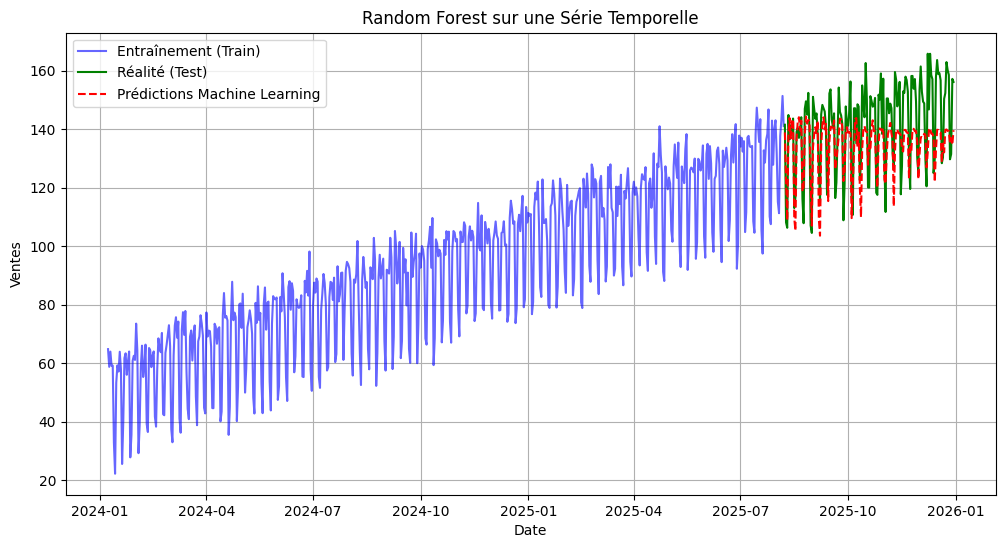

In [132]:
# Visualisation

import matplotlib.pyplot as plt


plt.figure(figsize= (12,6))

plt.plot(y_train, label="Entraînement (Train)", color="blue", alpha=0.6)
plt.plot(y_test, label="Réalité (Test)", color="green")
plt.plot(y_pred, label="Prédictions Machine Learning", color="red", linestyle="--")


plt.title("Random Forest sur une Série Temporelle")
plt.xlabel("Date")
plt.ylabel("Ventes")

plt.legend()
plt.grid(True)
plt.show()